# Agents, Session 8: AI Communication Protocols and Building an MCP Server

## One tool, every AI app

Over the last sessions, DilSeTrips gained tools: weather, a travel guide, flight search. But each tool was written *for our code*: our LangChain agents could use them, and nothing else could. If another AI app wanted the same weather tool, someone would have to rewrite it for that app.

The **Model Context Protocol (MCP)** fixes that. Write a tool once as an **MCP server**, and any app that speaks MCP (Claude Desktop, IDEs, your own agents) can use it. It's like USB-C: one standard plug instead of a different cable for every device.

Today you'll:

1. understand what a communication protocol is, and what MCP standardises;
2. tell apart the **host**, the **MCP client** and the **MCP server**;
3. build an MCP server with **FastMCP**, with tools, resources and prompts;
4. test it with a real MCP client, right here in the notebook;
5. connect it to **Claude Desktop**.

This notebook needs **no API key**. It runs in Google Colab and in VS Code; the Claude Desktop part needs your own computer.

### Setup

*VS Code users: use a separate virtual environment for this session. FastMCP needs a newer version of the `mcp` library than CrewAI (Sessions 6 and 7) can use, so installing both together breaks CrewAI.*

In [ ]:
%pip install -q fastmcp

In [ ]:
import json
import os
import sys
from pathlib import Path
from fastmcp import FastMCP, Client
from fastmcp.prompts import Message

import fastmcp
print("FastMCP version:", fastmcp.__version__)

## 1. Communication protocols

A **communication protocol** is an agreed set of rules for how systems exchange messages: how a message is formatted, how it's sent and acknowledged, and what happens when something goes wrong. Like traffic rules: who goes first, what the signals mean, what to do when someone doesn't move.

Protocols give us:

- **Consistency:** a request always has the same shape, so anyone can read it.
- **Reliability:** clear rules for errors, retries and timeouts.
- **Interoperability:** a Python client can talk to a server written in any language, because both follow the same rules.
- **Security:** rules about who may send which messages.
- **Scalability:** many components can work together without chaos.

Two protocols are shaping AI systems right now:

- **A2A (Agent-to-Agent):** lets AI agents talk to *each other* as peers: exchanging messages, delegating tasks, coordinating. (We only mention it today.)
- **MCP (Model Context Protocol):** connects AI *applications* to *tools and data*, in a client-server style. That's today's topic.

## 2. What MCP is

MCP is an open standard, introduced by Anthropic, for connecting AI applications to external tools, data and services in a structured way.

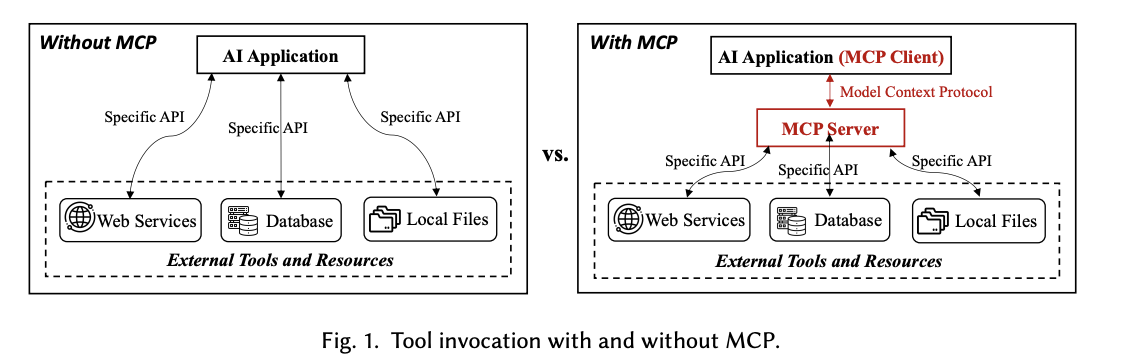

*Without MCP, every AI application needs its own custom connection to every tool. With MCP, tools sit behind MCP servers, and any MCP-speaking application can use them.*

### Function calling, tool calling and MCP

These three are easy to confuse:

| | What it is | Analogy |
|---|---|---|
| **Function calling** | A feature of one LLM's API: the model outputs JSON saying which function to call, and your code runs it | One brand of soda |
| **Tool calling** | The general idea, as frameworks use it: a "tool" can be any function or API (Sessions 1 to 7) | Soda in general |
| **MCP** | A *standard* for offering tools, data and prompts through servers, so any MCP client can use them | USB-C: one plug for every device |

Function calling and tool calling are about how *a model asks for* an action. MCP is about how tools are *packaged and shared* so that any AI application can find and use them.

## 3. Host, client and server

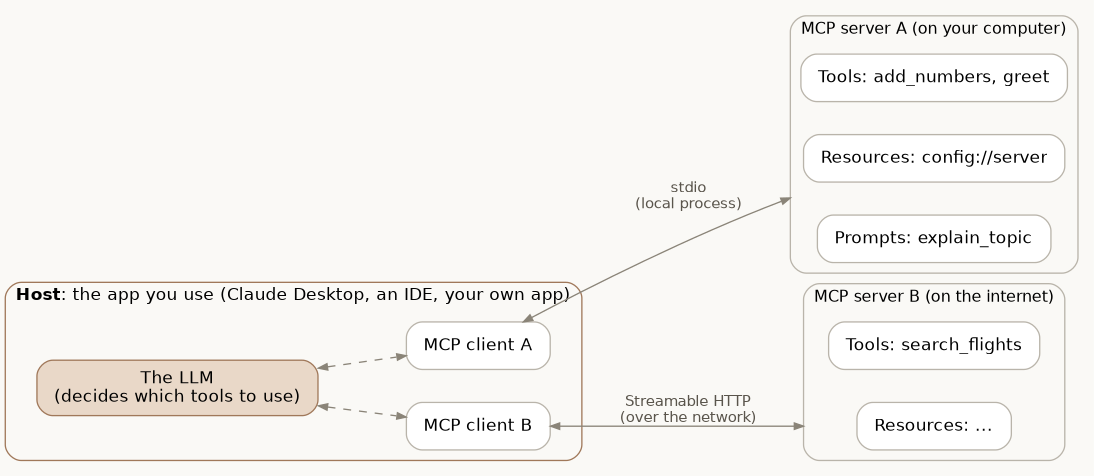

*The host app contains the LLM and one MCP client per server. Each client talks to exactly one server.*

- **Host:** the application you use, such as Claude Desktop, an IDE, or your own app. It contains the LLM and manages the conversation.
- **MCP client:** a component inside the host. Each client keeps one connection to one server, sends it requests, and receives its responses.
- **MCP server:** your code. It offers **tools**, **resources** and **prompts**, and answers the client's requests. It doesn't have to contain an LLM: the host's LLM decides when to use what the server offers.

Like a restaurant: the host is the restaurant, each client is a waiter, and each server is a kitchen that can make certain dishes.

### What a message looks like

MCP messages use **JSON-RPC 2.0**, a simple, well-known format. When Claude decides to call your `add_numbers` tool, its client sends something like:

```json
{"jsonrpc": "2.0", "id": 7, "method": "tools/call",
 "params": {"name": "add_numbers", "arguments": {"a": 2, "b": 3}}}
```

and your server replies:

```json
{"jsonrpc": "2.0", "id": 7,
 "result": {"content": [{"type": "text", "text": "5.0"}], "isError": false}}
```

The same `id` links the reply to the request. Other methods follow the same pattern: `tools/list`, `resources/read`, `prompts/get`. And when something fails, the reply carries a standard `error` with a code and a message, instead of a `result`. FastMCP writes and reads all of this for you.

## 4. What a server offers: tools, resources and prompts

| Feature | What it is | Examples | Who decides to use it |
|---|---|---|---|
| **Tools** | Actions the model can call: calculations, API calls, writing to a database | Search flights, send a message | **The model** |
| **Resources** | Read-only information that gives context | A file's contents, a config, a database schema | **The application** |
| **Prompts** | Ready-made instruction templates | "Plan a vacation", "Summarize my notes" | **The user** (picks one) |

## 5. What a client offers: elicitation, sampling and roots

Usually the client asks and the server answers. But MCP also lets a **server ask the client** for things, through three **client features**:

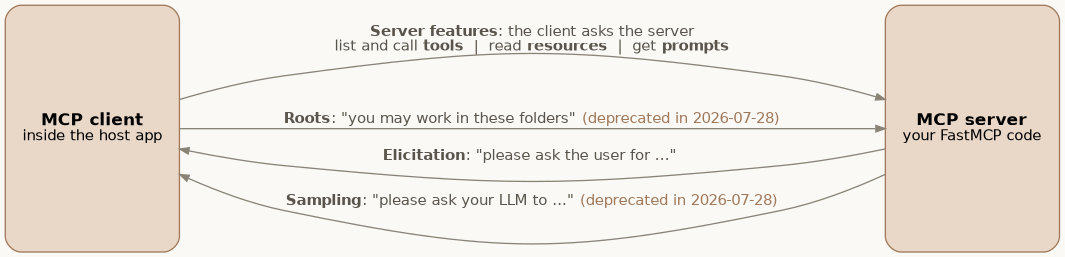

*Server features flow from client to server; client features let the server ask the client.*

| Client feature | What it means | Example (a travel-booking server) |
|---|---|---|
| **Elicitation** | The server asks the **user**, through the client, for missing information | "Which seat do you prefer: window or aisle?" |
| **Sampling** | The server asks the client's **LLM** to generate something, so the server needn't have its own model | "Here are 5 flights; pick the best one for this user" |
| **Roots** | The client tells the server which **folders or files** it may work with | "You may read the user's calendar folder" |

*Up to date as of late 2026: the MCP specification released on 28 July 2026 **deprecates sampling and roots**. Elicitation remains. You'll still see all three in older tutorials and tools.*

## 6. How messages travel: transports

The protocol defines the *messages*; a **transport** carries them. MCP has two standard transports:

- **stdio:** the client starts the server as a local program and they talk through its standard input and output. No network involved. Simple and private: ideal for servers on your own computer. **Claude Desktop uses this** for local servers.
- **Streamable HTTP:** the server runs as a web service and clients connect over the network. For remote servers, many users, and cloud deployment.

**Security, once a server is on a network:** don't expose dangerous tools (deleting files, running commands) without authentication; keep secrets in environment variables, never in code; treat every tool input as untrusted and validate it; avoid running user-supplied code; and use HTTPS. An MCP server is a door into your system.

## 7. Hands-on: build an MCP server with FastMCP

**FastMCP** is the most popular Python library for MCP. It handles the protocol (the JSON-RPC messages, the transports), so you just write ordinary Python functions.

### Step 1: create a server and add tools

A server is one line. A tool is a normal function with `@mcp.tool()` above it. Three things in the function become what clients see:

- the **function name** becomes the tool's name;
- the **type hints** (`a: float`) become the input rules, so a client can't send text where a number is expected;
- the **docstring** becomes the description the LLM reads to decide when to use the tool.

In [ ]:
mcp = FastMCP("Simple Math Server")

@mcp.tool()
def add_numbers(a: float, b: float) -> float:
    """Add two numbers together.

    Args:
        a: First number
        b: Second number
    """
    return a + b

@mcp.tool()
def multiply_numbers(a: float, b: float) -> float:
    """Multiply two numbers.

    Args:
        a: First number
        b: Second number
    """
    return a * b

@mcp.tool()
def greet(name: str) -> str:
    """Greet a person by name.

    Args:
        name: The person's name
    """
    return f"Hello, {name}! Welcome to the MCP server."

print("Server created:", mcp.name)

### Step 2: test it with an MCP client

FastMCP includes a real MCP **client**. `Client(mcp)` connects straight to the server object in this notebook, and talks to it with exactly the same protocol messages Claude Desktop would send.

`async with ... as client:` opens the connection and closes it at the end. `await` means "wait here for the server's answer". (Notebooks allow `await` directly in a cell.)

**Before you run it:** what do you think a client sees about each tool?

In [ ]:
async with Client(mcp) as client:
    tools = await client.list_tools()                  # sends a "tools/list" request
    for tool in tools:
        print(f"{tool.name}: {tool.description.splitlines()[0]}")

    print("\nWhat a client sees about add_numbers' inputs:")
    print(json.dumps(tools[0].input_schema, indent=2))

The client sees each tool's name, description, and an **input schema** built from your type hints and docstring. This is how Claude knows that `add_numbers` needs two numbers called `a` and `b`, and what each one means.

Now call the tools, as Claude would:

In [ ]:
async with Client(mcp) as client:
    result = await client.call_tool("add_numbers", {"a": 2, "b": 3})   # sends a "tools/call" request
    print("add_numbers(2, 3) =", result.data)
    result = await client.call_tool("multiply_numbers", {"a": 4, "b": 2.5})
    print("multiply_numbers(4, 2.5) =", result.data)
    result = await client.call_tool("greet", {"name": "Prasad"})
    print("greet('Prasad') =", result.data)

**Try it:** call `add_numbers` with `{"a": "two", "b": 3}`. The server refuses, because the input schema says `a` must be a number. Validation for free, from one type hint.

### Step 3: add resources

A **resource** is read-only information with an address (a URI) such as `config://server`. Tools *do* things; resources *provide* things to read. A function returning a dictionary is sent as JSON automatically.

In [ ]:
@mcp.resource("config://server")
def get_server_config() -> dict:
    """Get server configuration information."""
    return {"name": "Simple Math Server", "version": "1.0.0",
            "description": "A simple MCP server for basic math operations"}

@mcp.resource("resource://greeting")
def get_greeting() -> str:
    """Provides a simple greeting message."""
    return "Hello from FastMCP Resources!"

async with Client(mcp) as client:
    for resource in await client.list_resources():          # "resources/list"
        content = await client.read_resource(str(resource.uri))   # "resources/read"
        print(f"{resource.uri} -> {content[0].text}")

### Step 4: add prompts

A **prompt** is a ready-made instruction the *user* can pick in the client, filling in a few blanks. A prompt function returns either:

- a **string**: one message from the user (the simplest kind), or
- a **list of `Message` objects**: a short conversation, with `role="assistant"` for the assistant's turns.

*Note for older code: FastMCP 4 doesn't accept a single message object on its own; return a string or a list. Older tutorials also import `PromptMessage` from `fastmcp.prompts.prompt`, which no longer exists.*

In [ ]:
@mcp.prompt
def explain_topic(topic: str) -> str:
    """Asks the model to explain a study topic."""
    return f"Explain the concept of '{topic}' in simple terms with a short example."

@mcp.prompt
def generate_quiz(topic: str, difficulty: str = "easy") -> list[Message]:
    """Asks the model to create a few quiz questions for a topic."""
    return [Message(f"I'm studying {topic}. Can you quiz me?"),
            Message("Of course! What difficulty would you like?", role="assistant"),
            Message(f"{difficulty}. Please give 3 questions, each with 4 options, and say which answer is correct.")]

async with Client(mcp) as client:
    for prompt in await client.list_prompts():               # "prompts/list"
        print("Prompt:", prompt.name)
    rendered = await client.get_prompt("generate_quiz", {"topic": "MCP", "difficulty": "medium"})   # "prompts/get"
    print()
    for message in rendered.messages:
        print(f"{message.role}: {message.content.text}")

Our server now offers all three things: tools (actions), resources (information) and prompts (templates).

### Step 5: run the server as a real program, over stdio

Claude Desktop doesn't import your notebook; it **starts your server as a program** and talks to it over **stdio**. Let's do exactly that. `%%writefile` saves the cell as a file instead of running it.

In [ ]:
%%writefile study_server.py
from fastmcp import FastMCP

mcp = FastMCP("Study Server")

@mcp.tool()
def add_numbers(a: float, b: float) -> float:
    """Add two numbers together.

    Args:
        a: First number
        b: Second number
    """
    return a + b

@mcp.resource("config://server")
def get_server_config() -> dict:
    """Get server configuration information."""
    return {"name": "Study Server", "version": "1.0.0"}

@mcp.prompt
def explain_topic(topic: str) -> str:
    """Asks the model to explain a study topic."""
    return f"Explain the concept of '{topic}' in simple terms with a short example."

if __name__ == "__main__":
    mcp.run(transport="stdio")

Now connect to the **file**. `Client(Path("study_server.py"))` starts it as a separate program and talks to it through stdio: the same transport Claude Desktop uses. (`Path(...)` tells FastMCP "this is a file to run", not a web address.)

In [ ]:
async with Client(Path("study_server.py")) as client:    # starts the server program, connects over stdio
    print("Tools:", [tool.name for tool in await client.list_tools()])
    result = await client.call_tool("add_numbers", {"a": 10, "b": 32})
    print("add_numbers(10, 32) =", result.data)
    content = await client.read_resource("config://server")
    print("config://server ->", content[0].text)

That's a complete MCP round trip: a client started your server program, discovered what it offers, called a tool and read a resource, all through the protocol.

## 8. Connecting your server to Claude Desktop

**Claude Desktop** is a host app with a built-in MCP client. Once configured, Claude can use your tools while you chat. (The Claude model itself runs on Anthropic's servers; your MCP server runs on your own computer, and Claude Desktop connects the two.)

*This part needs your own computer (Windows or macOS) with Claude Desktop installed from [claude.ai/download](https://claude.ai/download). In Colab, read along; then do it in VS Code.*

### Step 1: get the configuration for your computer

Claude Desktop needs two things for each server: the **Python program** to use (your virtual environment's Python, where FastMCP is installed) and the **full path** to the server file. Wrong paths are the most common reason a server doesn't appear. This cell prints the exact configuration for this computer:

In [ ]:
config = {
    "mcpServers": {
        "study-server": {
            "command": sys.executable,                       # the Python this notebook is using
            "args": [os.path.abspath("study_server.py")],    # the full path to the server file
        }
    }
}
print(json.dumps(config, indent=2))

*In Colab, these paths point inside Colab's computer, so they won't work in Claude Desktop. Run this cell in VS Code on your own machine.*

### Step 2: add it to Claude Desktop

1. Open Claude Desktop, then **Settings > Developer > Edit Config**. This opens `claude_desktop_config.json` (on macOS in `~/Library/Application Support/Claude/`, on Windows in `%APPDATA%\Claude\`).
2. Paste the configuration from the cell above, and save. (If the file already has other servers, add `"study-server"` inside the existing `"mcpServers"` section.)
3. **Quit Claude Desktop completely and reopen it.** Closing the window isn't enough; it reads the configuration only when it starts.

### Step 3: check it's connected

In **Settings > Developer** your server should be listed with the status **running**:

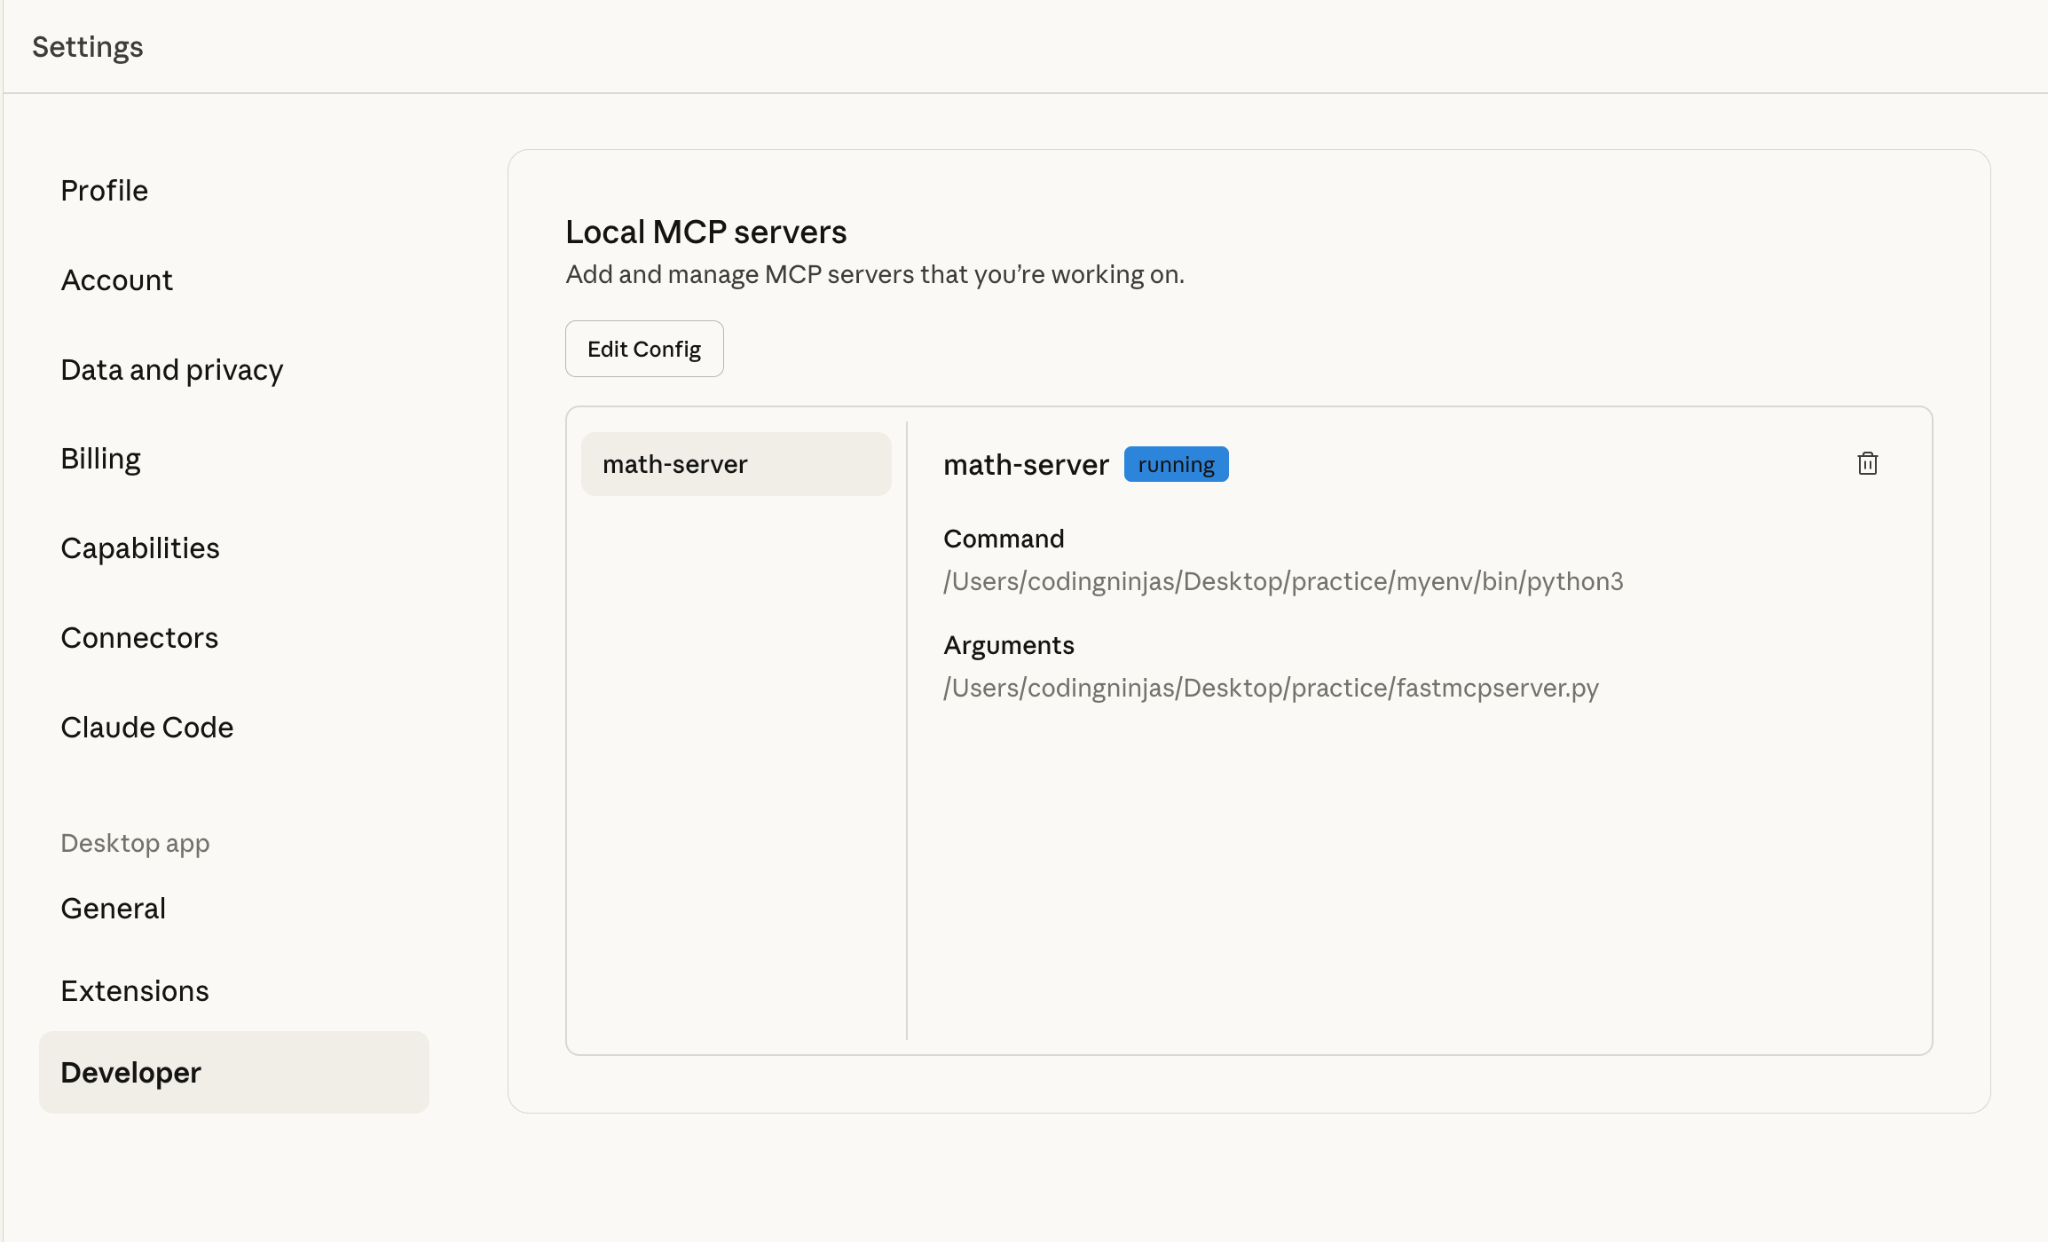

*A connected local MCP server in Claude Desktop's Developer settings, showing the command and the arguments.*

### Step 4: use it

Ask Claude something that needs your tool:

- "Use the study server to add 1234.5 and 678.9."
- "What tools does the study server have?"
- "Read the study server's configuration."

Claude will ask permission before calling your tool the first time. Prompts appear in Claude Desktop's attachment ("+") menu, where you pick one and fill in its blanks.

**If the server doesn't appear:** check the paths (use the printed configuration, not one typed by hand); make sure FastMCP is installed in *that* Python; restart Claude Desktop fully; and read Claude Desktop's MCP log files (macOS: `~/Library/Logs/Claude/`; Windows: `%APPDATA%\Claude\logs\`) for the error message.

## 9. Part 1 recap, and what's next

- **MCP** is a standard way for AI applications to use tools and data: a **host** contains the LLM, each **client** talks to one **server**.
- A server offers **tools** (actions), **resources** (information) and **prompts** (templates). **FastMCP** turns ordinary functions into all three.
- Servers run locally over **stdio** or remotely over **Streamable HTTP**, and **Claude Desktop** can use them in conversation.

**Next, in Part 2** (`Agents_Session_8_Part2_MCP_with_CrewAI_and_A2A.ipynb`): give a **CrewAI** agent tools from an MCP server, then meet **A2A**, the protocol for agents talking to other agents. The session's conclusions are at the end of Part 2.

## Exercises

1. **[Easy]** Add a `subtract_numbers` tool to `study_server.py`. Test it with `Client(Path("study_server.py"))` before trying it in Claude Desktop.
2. **[Easy]** Add a resource `data://courses` that returns a list of three course names. Read it with the client.
3. **[Medium]** Add a prompt `plan_revision(subject, days)` that returns a two-message conversation asking for a revision plan.
4. **[Medium]** Turn Session 6's weather tool into an MCP tool: copy `get_weather_forecast` (Open-Meteo, no key needed) into `study_server.py` with `@mcp.tool()`. Then ask Claude Desktop, "What's the weather in Manali this week?"
5. **[Discussion]** Which of your tools from earlier sessions would be dangerous to expose over HTTP without authentication? Why?

## Quick reference

| Idea | Code |
|---|---|
| Create a server | `mcp = FastMCP("Name")` |
| A tool (an action) | `@mcp.tool()` above a function with type hints and a docstring |
| A resource (information) | `@mcp.resource("config://name")` |
| A prompt (a template) | `@mcp.prompt`, returning a string or a list of `Message` |
| Run over stdio | `mcp.run(transport="stdio")` |
| Test with a client | `async with Client(mcp) as client:` or `Client(Path("server.py"))` |
| List / call / read / get | `list_tools()`, `call_tool(name, args)`, `read_resource(uri)`, `get_prompt(name, args)` |
| Claude Desktop config | `{"mcpServers": {"name": {"command": python_path, "args": [server_path]}}}` |